# Part B · Real Data — Saraga Hindustani + SSL Embeddings
### Raga, time-window, and context-fusion experiments on actual recordings

**Author:** Dr. Sudipta Bhattacharya · Dept. of CSE (AIML), IEM Kolkata · Companion to Part A (`raga_time_location_emotion.ipynb`)

This notebook runs the paper's **real-data experiments** and fills the abstract's [N], [K], [XX.X] placeholders:

| Exp | Question | Paper section |
|---|---|---|
| B1 | Raga identity from tonic-normalized pitch distributions (artist-disjoint, permutation-tested) | §5–§7, abstract |
| B2 | **Is Bhatkhande's svara–samay correlation audible?** — theoretical time-class from pitch content | §7 |
| B3 | Plumbing check only — synthetic context fusion with **label leakage by construction**; never cite | — |

**Runtime modes (auto-detected, printed in §3):**
- **REAL** (Colab, GPU runtime recommended): downloads Saraga Hindustani 1.5 via `mirdata` (≈15 GB zip from Zenodo; allow 30–60 min), embeds with wav2vec 2.0 (or MERT/log-mel, configurable), caches embeddings so re-runs skip straight to training.
- **SMOKE** (no network/data): a synthetic 48-recording corpus with class-structured timbres validates the entire pipeline end-to-end in ~3 min. Every function is identical; only the data source changes.

> ⚠️ The raga→time-window table in §2 encodes standard *samay* assignments and is **editable** — verify against your preferred reference (e.g., Bhatkhande) before submission. Seasonal/flexible ragas are excluded from time supervision.

## 1 · Setup and configuration

In [1]:
import sys, subprocess, importlib
def ensure(pkg, pip_name=None):
    try: importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or pkg], check=False)
for p, n in [("mirdata", None), ("librosa", None), ("sklearn", "scikit-learn")]:
    ensure(p, n)

import os, json, glob, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from scipy import stats
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 7
np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

# ------------------------- configuration -------------------------
FORCE_SMOKE   = False          # True -> skip downloads, run synthetic validation
EMBED_BACKEND = "auto"         # "auto"(=chroma) | "chroma" | "chroma+wav2vec2" | "wav2vec2" | "mert" | "melstats"
SEG_SECONDS   = 30.0           # segment length
MAX_SEG_PER_TRACK = 40         # cap segments per recording (chroma is cheap; raise freely)
MIN_TRACKS_PER_RAGA = 3        # filter: ragas with fewer recordings dropped
SEEDS_B = (7, 17, 27)          # pipeline-check; use (7,17,27,37,47) for the paper run
DATA_HOME = "/content/saraga" if os.path.isdir("/content") else "./saraga_data"
CACHE_DIR = None               # set after optional Drive mount below

# Optional: cache embeddings to Drive so re-runs skip extraction (~tens of MB)
try:
    from google.colab import drive  # noqa
    drive.mount("/content/drive")
    CACHE_DIR = "/content/drive/MyDrive/raga_paper_cache"
except Exception:
    CACHE_DIR = "./emb_cache"
os.makedirs(CACHE_DIR, exist_ok=True)
print("embedding cache:", CACHE_DIR)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
PAL = {"blue": "#2a78d6", "orange": "#eb6834"}

device: cpu
embedding cache: ./emb_cache


## 2 · Raga → canonical time-window table and pipeline core

One row per raga: the *samay* window (six classes as in Part A). `None` marks seasonal/flexible ragas (Malhar family, Basant/Bahar, light forms) — excluded from time-supervised experiments. Saraga's IAST-transliterated names ("Bāgēśrī", "Bhūp") are resolved by diacritic-stripped slugs plus the `EXTRA_SLUGS` alias table; §3 prints any name that still fails to resolve. **Edit freely; everything downstream recomputes.**

In [2]:
# Unified source-cited table (v2) — see unified_raga_samay.csv for per-raga
# sources (Bhatkhande KPM / Kaufmann 1968 / Bor et al. 1999) and dispute notes.
# status: fixed = time-supervisable | anytime (Bhairavi: sarva-kalika concluding
# raga) | light (thumri-anga vehicles) | seasonal (Malhar family, Basant/Bahar,
# monsoon-associated Desh, spring Hindol) | imported (Carnatic/modern: assigned
# time is concert habit, no traditional Hindustani samay).
# Only status == "fixed" enters time-supervised experiments; ALL statuses stay
# in the raga-identity experiment (B1).
UNIFIED = {
    "Lalit": ("dawn", "fixed"), "Ramkali": ("dawn", "fixed"),
    "Bhatiyar": ("dawn", "fixed"), "Bhairav": ("dawn", "fixed"),
    "Ahir Bhairav": ("dawn", "fixed"), "Vibhas": ("dawn", "fixed"),
    "Kalingada": ("dawn", "fixed"), "Sohini": ("dawn", "fixed"),
    "Bairagi": ("dawn", "fixed"), "Paraj": ("dawn", "fixed"),
    "Lalita Pancham": ("dawn", "fixed"),
    "Deshkar": ("morning", "fixed"), "Jaunpuri": ("morning", "fixed"),
    "Bilaskhani Todi": ("morning", "fixed"), "Gujari Todi": ("morning", "fixed"),
    "Miyan ki Todi": ("morning", "fixed"), "Komal Rishabh Asavari": ("morning", "fixed"),
    "Alhaiya Bilaval": ("morning", "fixed"), "Desi": ("morning", "fixed"),
    "Gaud Sarang": ("midday", "fixed"), "Shuddha Sarang": ("midday", "fixed"),
    "Brindabani Sarang": ("midday", "fixed"), "Bhimpalasi": ("midday", "fixed"),
    "Multani": ("midday", "fixed"), "Patdeep": ("midday", "fixed"),
    "Madhuvanti": ("midday", "fixed"), "Dhani": ("midday", "fixed"),
    "Gauri": ("dusk", "fixed"), "Purvi": ("dusk", "fixed"),
    "Shree": ("dusk", "fixed"), "Marwa": ("dusk", "fixed"),
    "Puriya": ("dusk", "fixed"), "Puriya Dhanashree": ("dusk", "fixed"),
    "Yaman": ("evening", "fixed"), "Bhoopali": ("evening", "fixed"),
    "Shuddha Kalyan": ("evening", "fixed"), "Jait Kalyan": ("evening", "fixed"),
    "Puriya Kalyan": ("evening", "fixed"), "Kedar": ("evening", "fixed"),
    "Hameer": ("evening", "fixed"), "Chhayanat": ("evening", "fixed"),
    "Khamaj": ("evening", "fixed"), "Jhinjhoti": ("evening", "fixed"),
    "Durga": ("night", "fixed"), "Bihag": ("night", "fixed"),
    "Maru Bihag": ("night", "fixed"), "Jaijaivanti": ("night", "fixed"),
    "Bageshri": ("night", "fixed"), "Rageshri": ("night", "fixed"),
    "Shankara": ("night", "fixed"), "Nand": ("night", "fixed"),
    "Tilak Kamod": ("night", "fixed"), "Khambavati": ("night", "fixed"),
    "Gorakh Kalyan": ("night", "fixed"), "Darbari": ("night", "fixed"),
    "Adana": ("night", "fixed"), "Malkauns": ("night", "fixed"),
    "Chandrakauns": ("night", "fixed"), "Jogkauns": ("night", "fixed"),
    "Shahana": ("night", "fixed"),
    "Bhairavi": ("anytime", "anytime"),
    "Kafi": ("anytime", "light"), "Pilu": ("anytime", "light"),
    "Tilang": ("anytime", "light"), "Mand": ("anytime", "light"),
    "Gavti": ("anytime", "light"), "Sindhura": ("anytime", "light"),
    "Gara": ("anytime", "light"),
    "Miyan Malhar": ("night", "seasonal"), "Gaud Malhar": ("night", "seasonal"),
    "Ramdasi Malhar": ("night", "seasonal"), "Megh": ("night", "seasonal"),
    "Desh": ("night", "seasonal"), "Basant": ("dawn", "seasonal"),
    "Bahar": ("night", "seasonal"), "Basanti Kedar": ("evening", "seasonal"),
    "Hindol": ("morning", "seasonal"), "Hindol Pancham": ("morning", "seasonal"),
    "Hansadhwani": ("evening", "imported"), "Kirwani": ("night", "imported"),
    "Kalavati": ("night", "imported"), "Abhogi": ("night", "imported"),
    "Jog": ("night", "imported"),
    # added after the first REAL run surfaced Saraga's full inventory
    "Jogiya": ("dawn", "fixed"), "Khat": ("morning", "fixed"),
    "Nat Bhairav": ("dawn", "fixed"), "Nat Kamod": ("night", "fixed"),
    "Suha": ("midday", "fixed"), "Madhukauns": ("night", "fixed"),
    "Saraswati": ("evening", "imported"), "Majh Khamaj": ("anytime", "light"),
}
WINDOW_ORDER = ["dawn", "morning", "midday", "dusk", "evening", "night"]

import unicodedata, re
def normalize_raga_name(name):
    s = " ".join(str(name).strip().split())
    return s[:1].upper() + s[1:].lower() if s else s

def slugify(name):
    '''Diacritic-insensitive key: 'Bāgēśrī' -> 'bagesri', 'Bhūp' -> 'bhup'.'''
    s = unicodedata.normalize("NFD", str(name))
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    return re.sub(r"[^a-z]", "", s.lower())

# Saraga-1.5 IAST spelling aliases: slug -> canonical name in UNIFIED.
# Each merge is an editorial decision; notable ones: Todi -> Miyan ki Todi
# (standard), Bibhas -> Vibhas, Yaman Kalyan -> Yaman (purist distinction noted
# in the paper), Darbari Kanada -> Darbari. EDITABLE.
ALIASES = {
    "ahirabhairav": "Ahir Bhairav", "bibhas": "Vibhas", "bhup": "Bhoopali",
    "bhupali": "Bhoopali", "bhimapalas": "Bhimpalasi",
    "bilasakhanitodi": "Bilaskhani Todi", "bagesri": "Bageshri",
    "candrakauns": "Chandrakauns", "des": "Desh", "hamir": "Hameer",
    "hindolpancam": "Hindol Pancham", "jaitkalyan": "Jait Kalyan",
    "marva": "Marwa", "marubihag": "Maru Bihag",
    "puriyadhanasri": "Puriya Dhanashree", "puriyakalyan": "Puriya Kalyan",
    "ragesri": "Rageshri", "suddhsarang": "Shuddha Sarang",
    "sohani": "Sohini", "todi": "Miyan ki Todi", "miyankitodi": "Miyan ki Todi",
    "darbarikanada": "Darbari", "sri": "Shree", "jayjayvanti": "Jaijaivanti",
    "jaijaiwanti": "Jaijaivanti", "sankara": "Shankara",
    "komalrisabhasavari": "Komal Rishabh Asavari", "patdip": "Patdeep",
    "chayanat": "Chhayanat", "hansadhvani": "Hansadhwani", "kirvani": "Kirwani",
    "suddhakalyan": "Shuddha Kalyan", "suddhkalyan": "Shuddha Kalyan",
    "yamankalyan": "Yaman", "ramkeli": "Ramkali", "lalitapancam": "Lalita Pancham",
    "gaudmalhar": "Gaud Malhar", "miyanmalhar": "Miyan Malhar",
    "ramdasimalhar": "Ramdasi Malhar", "malhar": "Miyan Malhar",
    "basantikedar": "Basanti Kedar", "alhaiyabilaval": "Alhaiya Bilaval",
    "mishrapilu": "Pilu",
    # misses surfaced by the first REAL run (IAST variants + chandrabindu)
    "kiravani": "Kirwani", "komalrisabhasaveri": "Komal Rishabh Asavari",
    "lalitpancam": "Lalita Pancham", "miyammalhar": "Miyan Malhar",
    "misrakalingada": "Kalingada", "misrapilu": "Pilu",
    "majhkhamaj": "Majh Khamaj", "natbhairav": "Nat Bhairav",
    "natkamod": "Nat Kamod", "jogiya": "Jogiya", "kalyan": "Yaman",
    "khata": "Khat", "madhukauns": "Madhukauns", "sarasvati": "Saraswati",
    "suha": "Suha",
}

def _slug_map():
    m = {slugify(k): k for k in UNIFIED}
    for s, name in ALIASES.items():
        m.setdefault(s, name)
    return m

def resolve_raga(name):
    '''-> (canonical display name, window, status); unmapped -> UNKNOWN.'''
    canon = _slug_map().get(slugify(name))
    if canon is None or canon not in UNIFIED:
        return normalize_raga_name(name), "UNKNOWN", "unknown"
    w, st = UNIFIED[canon]
    return canon, w, st

def extract_raga_from_track(track):
    md_ = None
    for attr in ("metadata", "_track_metadata"):
        try:
            md_ = getattr(track, attr)
            if md_: break
        except Exception: continue
    if not isinstance(md_, dict): return None
    for key in ("raags", "raaga", "raga"):
        v = md_.get(key)
        if not v: continue
        if isinstance(v, str): return v
        if isinstance(v, (list, tuple)) and v:
            f = v[0]
            return (f.get("name") or f.get("common_name")) if isinstance(f, dict) else str(f)
        if isinstance(v, dict): return v.get("name") or v.get("common_name")
    return None

def extract_artist(track, fallback):
    '''Artist string for artist-disjoint splits (defensive across metadata layouts).'''
    md_ = None
    for attr in ("metadata", "_track_metadata"):
        try:
            md_ = getattr(track, attr)
            if md_: break
        except Exception: continue
    if isinstance(md_, dict):
        for key in ("album_artists", "artists", "artist"):
            v = md_.get(key)
            if not v: continue
            names = []
            for item in (v if isinstance(v, (list, tuple)) else [v]):
                if isinstance(item, dict):
                    nm = item.get("name") or (item.get("artist") or {}).get("name")
                    if nm: names.append(str(nm))
                elif isinstance(item, str):
                    names.append(item)
            if names: return " & ".join(sorted(set(names)))
    return f"unknown::{fallback}"

def build_track_table(tracks):
    rows = []
    for tid, tr in tracks.items():
        raga_raw = extract_raga_from_track(tr)
        if raga_raw is None: continue
        raga, window, status = resolve_raga(raga_raw)
        try:
            tonic = float(getattr(tr, "tonic", None) or 0) or None   # Saraga ctonic.txt, Hz
        except Exception:
            tonic = None
        rows.append({"track_id": tid, "audio_path": getattr(tr, "audio_path", None),
                     "raga_raw": str(raga_raw), "raga": raga, "window": window,
                     "status": status, "artist": extract_artist(tr, tid), "tonic": tonic})
    return pd.DataFrame(rows)

def filter_table(df, min_tracks_per_raga=3, require_window=True):
    out = df.copy()
    if require_window:   # time supervision: window known AND status 'fixed'
        out = out[out.window.isin(WINDOW_ORDER) & (out.status == "fixed")]
    counts = out.raga.value_counts()
    return out[out.raga.isin(counts[counts >= min_tracks_per_raga].index)].reset_index(drop=True)

def segment_signal(y, sr, seg_s=30.0, max_segments=None):
    n = int(seg_s * sr)
    segs = [y[i:i+n] for i in range(0, len(y) - n + 1, n)]
    return segs[:max_segments] if max_segments else segs

def recording_disjoint_split(y, groups, test_size=0.3, seed=7):
    gss = GroupShuffleSplit(n_splits=1, test_size=test_size, random_state=seed)
    itr, ite = next(gss.split(np.zeros(len(y)), y, groups))
    seen = set(y[itr])
    return itr, ite[np.isin(y[ite], list(seen))]

from collections import Counter
print("unified table:", dict(Counter(st for _, st in UNIFIED.values())),
      "| only status='fixed' is time-supervised; all statuses enter raga-ID (B1)")

unified table: {'fixed': 66, 'anytime': 1, 'light': 8, 'seasonal': 10, 'imported': 6} | only status='fixed' is time-supervised; all statuses enter raga-ID (B1)


## 3 · Data acquisition — Saraga Hindustani 1.5, with graceful fallback

Tries the real corpus first (`mirdata` → Zenodo, open access). On any failure — no network, no disk, `FORCE_SMOKE=True` — it builds the synthetic smoke corpus so the rest of the notebook still validates end-to-end. The banner printed here states which mode this run used; **only REAL-mode numbers go into the paper.**

In [3]:
MODE = "SMOKE"
tracks, audio_bank = {}, {}

if not FORCE_SMOKE:
    try:
        import mirdata
        saraga = mirdata.initialize("saraga_hindustani", data_home=DATA_HOME)
        saraga.download()           # ~15 GB zip; resumes if partially present
        bad = saraga.validate(verbose=False)
        tracks = {tid: saraga.track(tid) for tid in saraga.track_ids}
        MODE = "REAL"
        print(f"Saraga Hindustani loaded: {len(tracks)} recordings")
    except Exception as e:
        print(f"[real data unavailable: {type(e).__name__}: {str(e)[:160]}]")

if MODE == "SMOKE":
    rng = np.random.default_rng(0)
    class _T:
        def __init__(self, tid, raga):
            self.audio_path = tid
            self.metadata = {"raags": [{"name": raga}]}
    sr0, dur = 22050, 70.0
    t = np.arange(int(dur * sr0)) / sr0
    n_ragas, per = 12, 4
    for i in range(n_ragas):
        raga = f"Testraga{chr(97+i)}"
        UNIFIED[normalize_raga_name(raga)] = (WINDOW_ORDER[i % 6], "fixed")
        f0, H = 110.0 * 2 ** (i / n_ragas), 1 + (i % 4)
        for k in range(per):
            tid = f"{raga}_{k}"
            y = sum(np.sin(2*np.pi*f0*h*t + rng.uniform(0, 6.28))/h for h in range(1, H+1))
            y = ((y + 0.05*rng.standard_normal(len(t)))
                 * (1 + 0.002*np.sin(2*np.pi*(0.5+0.1*k)*t))).astype(np.float32)
            audio_bank[tid] = (y, sr0)
            tracks[tid] = _T(tid, raga)
    print(f"synthetic smoke corpus built: {len(tracks)} 'recordings'")

print(f"\n=========== RUN MODE: {MODE} ===========")
if MODE == "SMOKE":
    print("(pipeline-validation numbers only — NOT for the paper)")

0.00B [00:00, ?B/s]

ERROR: 
                            mirdata failed to download the dataset from https://zenodo.org/record/4301737/files/saraga1.5_hindustani.zip?download=1!
                            Please try again in a few minutes.
                            If this error persists, please raise an issue at
                            https://github.com/mir-dataset-loaders/mirdata,
                            and tag it with 'broken-link'.
                            


0.00B [00:00, ?B/s]

[real data unavailable: URLError: <urlopen error Tunnel connection failed: 403 Forbidden>]


synthetic smoke corpus built: 48 'recordings'

=========== RUN MODE: SMOKE ===========
(pipeline-validation numbers only — NOT for the paper)


In [4]:
table = build_track_table(tracks)
unmapped = sorted(table.loc[table.window == "UNKNOWN", "raga_raw"].unique())
print(f"recordings with raga metadata: {len(table)}  |  distinct ragas (after alias merge): {table.raga.nunique()}")
print(f"unmapped raga names (extend ALIASES in §2!): {len(unmapped)}")
for u in unmapped: print("   ", u)

# B1 uses every raga with enough recordings — no window needed for identity
table_f = filter_table(table, MIN_TRACKS_PER_RAGA, require_window=False)
N_REC, K_RAGAS = table_f.track_id.nunique(), table_f.raga.nunique()
N_ART = table_f.artist.nunique()
# B2/B3 additionally need status 'fixed' (anytime/light/seasonal/imported excluded)
tab_w = table_f[table_f.window.isin(WINDOW_ORDER) & (table_f.status == "fixed")]
N_W, K_W = tab_w.track_id.nunique(), tab_w.raga.nunique()

print(f"\nB1 set  (≥{MIN_TRACKS_PER_RAGA} rec/raga)          : N = {N_REC} recordings, K = {K_RAGAS} ragas, "
      f"{N_ART} distinct artists (splits are ARTIST-disjoint)")
print(f"B2/B3 set (status='fixed' subset): N = {N_W} recordings, K = {K_W} ragas")
cnt2 = (table.raga.value_counts() >= 2).sum()
print(f"(with MIN_TRACKS_PER_RAGA=2 the B1 set would have {cnt2} ragas — trade-off: "
      f"1 train/1 test recording per raga)")
display(tab_w.groupby("window").agg(ragas=("raga", "nunique"), recordings=("track_id", "count"))
        .reindex(WINDOW_ORDER).fillna(0).astype(int))
display(table_f.raga.value_counts().rename("recordings").to_frame().T)

recordings with raga metadata: 48  |  distinct ragas (after alias merge): 12
unmapped raga names (extend ALIASES in §2!): 0

B1 set  (≥3 rec/raga)          : N = 48 recordings, K = 12 ragas, 48 distinct artists (splits are ARTIST-disjoint)
B2/B3 set (status='fixed' subset): N = 48 recordings, K = 12 ragas
(with MIN_TRACKS_PER_RAGA=2 the B1 set would have 12 ragas — trade-off: 1 train/1 test recording per raga)


,ragas,recordings
window,,
dawn,2,8
morning,2,8
midday,2,8
dusk,2,8
evening,2,8
night,2,8


raga,Testragaa,Testragab,Testragac,Testragad,Testragae,Testragaf,Testragag,Testragah,Testragai,Testragaj,Testragak,Testragal
recordings,4,4,4,4,4,4,4,4,4,4,4,4


## 4 · Feature extraction (cached) — cent-resolution tonic-normalized pitch distributions

**Why pitch distributions, not a speech SSL model.** A raga is defined by its svara material *relative to the tonic* (Sa), which varies per artist. The field's standard features are **tonic-normalized pitch distributions** on the CompMusic lineage — Chordia & Rae 2007 (pitch-class distributions), Koduri et al. 2012/14 (fine-grained KDE distributions), Gulati et al. 2016 (TDMS, the standard baseline to compare against in the paper). Saraga ships **predominant-melody and tonic annotations**, so the primary backend here builds a **120-bin, 10-cent-resolution folded pitch histogram** directly from the annotations (no audio decoding) — intonation-aware where 12-bin chroma is not. A speech SSL model (wav2vec2) mean-pooled over 30 s scored **at chance** on this corpus in an earlier run — kept only as a comparison backend. Known limitation, stated in the paper: distribution features discard melodic grammar (āroha/avaroha, pakad, gamaka), so allied ragas sharing a scale (Deshkar/Bhoopali/Shuddha Kalyan; Puriya/Marwa/Sohini) remain hard — report an allied-raga error analysis.

| `EMBED_BACKEND` | Features | Dim | Notes |
|---|---|---|---|
| `"pitchhist"` (auto in REAL) | 120-bin 10-cent folded histogram from melody+tonic annotations | 121 | **default**; annotation-based, fast |
| `"chroma"` (auto in SMOKE) | tonic-rotated CQT-chroma mean+std+median | 36 | audio-based fallback |
| `"chroma+wav2vec2"`, `"wav2vec2"`, `"mert"`, `"melstats"` | as named | — | comparison backends |

Each recording's segment features are cached per backend as one `.npz` in `CACHE_DIR`. Full-mix audio features are tabla/tanpura-contaminated around Sa–Pa; the annotation-based default avoids that. (Ālāp/gat section-aware analysis via Saraga's section annotations: planned extension.)

In [5]:
def chroma_embed_factory():
    import librosa
    C1 = 32.70319566257483                      # Hz
    def f(y, sr, tonic=None):
        ch = librosa.feature.chroma_cqt(y=y.astype(np.float32), sr=sr)   # [12, T]
        if tonic:                               # rotate: tonic pitch class -> bin 0
            tpc = int(round(12 * np.log2(tonic / C1))) % 12
            ch = np.roll(ch, -tpc, axis=0)
        return np.concatenate([ch.mean(1), ch.std(1), np.median(ch, 1)]).astype(np.float32)
    return f, "chroma12tonic"

def melstats_embed_factory():
    import librosa
    def f(y, sr, tonic=None):
        S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmax=8000)
        L = np.log1p(S)
        return np.concatenate([L.mean(1), L.std(1)]).astype(np.float32)
    return f, "melstats"

def hf_embed_factory(model_name, target_sr=16000, trust=False):
    from transformers import AutoModel, AutoFeatureExtractor
    import librosa
    fe = AutoFeatureExtractor.from_pretrained(model_name, trust_remote_code=trust)
    net = AutoModel.from_pretrained(model_name, trust_remote_code=trust).to(DEVICE).eval()
    @torch.no_grad()
    def f(y, sr, tonic=None):
        if sr != target_sr:
            y = librosa.resample(y.astype(np.float32), orig_sr=sr, target_sr=target_sr)
        inp = fe(y, sampling_rate=target_sr, return_tensors="pt").to(DEVICE)
        return net(**inp).last_hidden_state.mean(1).squeeze(0).float().cpu().numpy()
    return f, model_name.split("/")[-1]

FACTORIES = {"chroma": chroma_embed_factory,
             "melstats": melstats_embed_factory,
             "wav2vec2": lambda: hf_embed_factory("facebook/wav2vec2-base"),
             "mert": lambda: hf_embed_factory("m-a-p/MERT-v1-95M", 24000, trust=True)}

if EMBED_BACKEND == "auto":
    want = ["pitchhist"] if MODE == "REAL" else ["chroma"]
else:
    want = EMBED_BACKEND.split("+")

USE_PITCHHIST = "pitchhist" in want
parts, names = [], []
for cand in [w for w in want if w != "pitchhist"]:
    try:
        f, nm = FACTORIES[cand]()
        parts.append(f); names.append(nm)
    except Exception as e:
        print(f"[{cand} unavailable: {type(e).__name__}: {str(e)[:120]}]")
if USE_PITCHHIST:
    names = ["pitchhist120"] + names
if not parts and not USE_PITCHHIST:              # last-resort fallback
    f, nm = melstats_embed_factory(); parts, names = [f], [nm]
def embed_fn(y, sr, tonic=None):
    return np.concatenate([p(y, sr, tonic) for p in parts])
EMB_NAME = "+".join(names)
print("embedding backend:", EMB_NAME)

NBINS, CENT_RES = 120, 10                       # folded octave at 10-cent resolution
def pitchhist_track(row, seg_s, max_segments):
    '''120-bin tonic-normalized folded pitch histogram per segment, from
    Saraga's predominant-melody annotation (F0) + ctonic. No audio needed.'''
    tr = tracks[row.track_id]
    p = tr.pitch
    if p is None: return None
    t_ann = np.asarray(p.times, dtype=float)
    f_ann = np.asarray(p.frequencies, dtype=float)
    voiced = f_ann > 20.0
    if voiced.sum() < 100: return None
    tonic = row.tonic if pd.notna(row.tonic) and row.tonic else np.median(f_ann[voiced])
    cents = (1200.0 * np.log2(f_ann[voiced] / tonic)) % 1200.0
    tv = t_ann[voiced]
    segs, t0 = [], 0.0
    while t0 + seg_s <= (tv.max() if len(tv) else 0) and len(segs) < max_segments:
        m = (tv >= t0) & (tv < t0 + seg_s)
        if m.sum() >= 200:                       # enough voiced frames
            h, _ = np.histogram(cents[m], bins=NBINS, range=(0, 1200))
            h = h / h.sum()
            segs.append(np.concatenate([h, [m.sum() / max(1, ((t_ann >= t0) & (t_ann < t0 + seg_s)).sum())]]))
        t0 += seg_s
    return np.vstack(segs).astype(np.float32) if segs else None

embedding backend: chroma12tonic


In [6]:
def load_audio(row):
    if MODE == "SMOKE":
        return audio_bank[row.track_id]
    import librosa
    y, sr = librosa.load(row.audio_path, sr=None, mono=True)
    return y, sr

def embed_track(row):
    key = f"{row.track_id.replace('/', '_')}__{EMB_NAME}__{int(SEG_SECONDS)}s.npz"
    path = os.path.join(CACHE_DIR, key)
    if os.path.exists(path):
        z = np.load(path)
        return z["E"]
    seg_s = SEG_SECONDS if MODE == "REAL" else 10.0
    max_seg = MAX_SEG_PER_TRACK if MODE == "REAL" else 6
    if USE_PITCHHIST:
        E = pitchhist_track(row, seg_s, max_seg)
        extra = []
        if E is not None and parts:              # optional concat backends
            y, sr = load_audio(row)
            segs = segment_signal(y, sr, seg_s, len(E))
            extra = np.vstack([embed_fn(s, sr, row.tonic) for s in segs[:len(E)]])
            E = np.hstack([E[:len(extra)], extra])
    else:
        y, sr = load_audio(row)
        segs = segment_signal(y, sr, seg_s, max_seg)
        if not segs: return None
        tonic = row.tonic if "tonic" in row and pd.notna(row.tonic) else None
        E = np.vstack([embed_fn(s, sr, tonic) for s in segs]).astype(np.float32)
    if E is None: return None
    np.savez_compressed(path, E=E.astype(np.float32))
    return E.astype(np.float32)

X_list, yr, yw, stat, groups, artists = [], [], [], [], [], []
for k, row in table_f.iterrows():
    try:
        E = embed_track(row)
    except Exception as e:
        print(f"  skip {row.track_id}: {type(e).__name__} {str(e)[:100]}"); continue
    if E is None:
        print(f"  skip {row.track_id}: no usable pitch annotation"); continue
    X_list.append(E)
    yr += [row.raga] * len(E); yw += [row.window] * len(E)
    stat += [row.status] * len(E)
    groups += [row.track_id] * len(E); artists += [row.artist] * len(E)
    if (k+1) % 10 == 0: print(f"  {k+1}/{len(table_f)} recordings embedded")

X = np.vstack(X_list)
yr, yw, stat, groups, artists = map(np.array, (yr, yw, stat, groups, artists))
N_SEG, D_EMB = X.shape
print(f"\nsegments: {N_SEG}  |  dim: {D_EMB}  |  recordings: {len(set(groups))}  |  "
      f"artists: {len(set(artists))}  |  backend: {EMB_NAME}")

  10/48 recordings embedded
  20/48 recordings embedded
  30/48 recordings embedded
  40/48 recordings embedded

segments: 288  |  dim: 36  |  recordings: 48  |  artists: 48  |  backend: chroma12tonic


## 5 · Shared model code (identical architecture/protocol to Part A)

In [7]:
class RagaFFNN(nn.Module):
    def __init__(self, d_in, n_classes, hidden=(256, 64), p_drop=0.3):
        super().__init__()
        h1, h2 = hidden
        self.net = nn.Sequential(
            nn.Linear(d_in, h1), nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(p_drop),
            nn.Linear(h2, n_classes))
    def forward(self, x): return self.net(x)

def train_ffnn(Xtr, ytr, Xva, yva, n_classes, epochs=200, lr=1e-3, bs=128):
    model = RagaFFNN(Xtr.shape[1], n_classes).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    lossf = nn.CrossEntropyLoss()
    Xtr_t, ytr_t = torch.tensor(Xtr, device=DEVICE), torch.tensor(ytr, device=DEVICE)
    Xva_t, yva_t = torch.tensor(Xva, device=DEVICE), torch.tensor(yva, device=DEVICE)
    # best initialized from the initial state so it is never None, even if
    # validation accuracy never improves (e.g., tiny/degenerate val split)
    best = {k: v.clone() for k, v in model.state_dict().items()}
    best_va, bad = -1.0, 0
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(len(Xtr_t), device=DEVICE)
        for i in range(0, len(Xtr_t), bs):
            idx = perm[i:i+bs]
            opt.zero_grad(); lossf(model(Xtr_t[idx]), ytr_t[idx]).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            va = (model(Xva_t).argmax(1) == yva_t).float().mean().item() if len(yva_t) else 0.0
        if np.isnan(va): va = 0.0            # empty/degenerate val -> no NaN poisoning
        if va > best_va: best_va, bad, best = va, 0, {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
            if bad >= 25: break
    model.load_state_dict(best); return model

@torch.no_grad()
def evaluate(model, X_, y_, k=3):
    model.eval()
    logits = model(torch.tensor(X_, device=DEVICE))
    pred = logits.argmax(1).cpu().numpy()
    kk = min(k, logits.shape[1])
    topk = logits.topk(kk, 1).indices.cpu().numpy()
    return {"acc": accuracy_score(y_, pred), "macro_f1": f1_score(y_, pred, average="macro"),
            "top3_acc": float(np.mean([y_[i] in topk[i] for i in range(len(y_))]))}, pred

def perm_chance_p(y_true, pred, n_perm=10000, rng=np.random.default_rng(3)):
    '''Permutation chance test: p = fraction of label-shuffles whose agreement
    with pred >= the observed accuracy (no refit; chance distribution of the
    test-set agreement under the null of no association).'''
    obs = (y_true == pred).mean()
    perm = np.array([(rng.permutation(y_true) == pred).mean() for _ in range(n_perm)])
    return obs, float((perm >= obs).mean() + 1/n_perm), perm.mean()

def split_groups(y, groups, seed):
    '''train/val/test with NO group shared across sides (~70/15/15 by segments).
    The val carve-out is a plain group split WITHOUT the seen-class filter:
    val only steers early stopping (unseen-class val items just score 0), and
    filtering it can empty the val set when groups are few — the class filter
    is applied only to the TEST side, where metrics are reported.'''
    itr_, ite = recording_disjoint_split(y, groups, test_size=0.30, seed=seed)
    gss = GroupShuffleSplit(n_splits=1, test_size=0.18, random_state=seed + 1)
    tr2, va2 = next(gss.split(np.zeros(len(itr_)), y[itr_], groups[itr_]))
    itr, iva = itr_[tr2], itr_[va2]
    assert not (set(groups[itr]) | set(groups[iva])) & set(groups[ite])
    assert not set(groups[itr]) & set(groups[iva])
    assert len(iva) > 0
    return itr, iva, ite

def zfit(Xtr): mu, sd = Xtr.mean(0), Xtr.std(0) + 1e-6; return lambda A: (A - mu) / sd
print("model code ready")

model code ready


## 6 · Experiment B1 — raga identity from pitch distributions

Segment-level classification with **artist-disjoint** train/val/test (stricter than recording-disjoint: the same performer never straddles a split, so voice timbre and venue acoustics cannot leak — in SMOKE mode each synthetic recording is its own artist, so this reduces to recording-disjoint), repeated over seeds, with a **permutation chance test** (label shuffles, no refit) rather than a bare 1/K figure.

*Calibration:* with 3–5 recordings per raga the test side holds ~1 recording per class — expect high seed variance; report mean ± std and the permutation p. For a K reviewers respect, the CompMusic Hindustani Raga Recognition corpus (~300 recordings / 30 ragas, the TDMS benchmark) is the right augmentation — same Hindustani tradition, unlike Carnatic, whose practice largely does not observe samay.

In [8]:
classes_r = sorted(set(yr))
y1 = np.array([classes_r.index(r) for r in yr])
res_b1, perm_b1 = [], []
for s in SEEDS_B:
    torch.manual_seed(s)
    itr, iva, ite = split_groups(y1, artists, s)
    z = zfit(X[itr]); Xn = z(X)
    mdl = train_ffnn(Xn[itr], y1[itr], Xn[iva], y1[iva], len(classes_r))
    m, pred1 = evaluate(mdl, Xn[ite], y1[ite])
    obs, p_perm, chance_emp = perm_chance_p(y1[ite], pred1)
    perm_b1.append(p_perm)
    res_b1.append(m); last_b1 = (ite, pred1)
    print(f"seed {s}: top-1 {m['acc']:.3f}  macro-F1 {m['macro_f1']:.3f}  "
          f"top-3 {m['top3_acc']:.3f}  perm-chance {chance_emp:.3f}, p = {p_perm:.4f}")
b1 = pd.DataFrame(res_b1).agg(["mean", "std"]).round(3)
print(f"\nB1 ({MODE}, {EMB_NAME}): {len(classes_r)} ragas | "
      f"permutation p per seed: {[round(p,4) for p in perm_b1]}")
display(b1)

seed 7: top-1 1.000  macro-F1 1.000  top-3 1.000  perm-chance 0.101, p = 0.0001
seed 17: top-1 0.467  macro-F1 0.379  top-3 1.000  perm-chance 0.076, p = 0.0001


seed 27: top-1 0.933  macro-F1 0.879  top-3 0.933  perm-chance 0.103, p = 0.0001

B1 (SMOKE, chroma12tonic): 12 ragas | permutation p per seed: [0.0001, 0.0001, 0.0001]


,acc,macro_f1,top3_acc
mean,0.800,0.753,0.978
std,0.291,0.329,0.038


## 7 · Experiment B2 — is Bhatkhande's svara–samay correlation audible?

**Reframed after review.** Saraga recordings are largely evening concerts, so this experiment does **not** test when the music was performed. What it tests: Bhatkhande's rationalized samay system correlates time-class with svara material *by design* (komal re–dha ⇒ sandhi-prakash; the madhyam as day/night marker) — so can a classifier recover a raga's **theoretical time-class** from its pitch distribution alone? Above-chance (by permutation test) = the codified svara–samay correlation is present in performed music; a cultural-analytics finding, not a performance-time claim. Labels use only `status = "fixed"` ragas (anytime/light/seasonal/imported excluded).

**Confound to report when K_fixed is small:** if a window class is carried by a single raga (e.g., dawn = Lalit alone), window prediction collapses into raga prediction. Report K ragas per window (printed below) and treat B2 as citable only when every retained window has ≥2 ragas — grow coverage via `MIN_TRACKS_PER_RAGA = 2` or the CompMusic corpus.

time-supervised subset: 288/288 segments, 48 recordings, 48 artists
ragas per window: {'dawn': np.int64(2), 'dusk': np.int64(2), 'evening': np.int64(2), 'midday': np.int64(2), 'morning': np.int64(2), 'night': np.int64(2)} — windows with 1 raga make B2 collapse into raga-ID (see note above)
seed 7: top-1 1.000  macro-F1 1.000  perm-chance 0.182, p = 0.0001


seed 17: top-1 1.000  macro-F1 1.000  perm-chance 0.200, p = 0.0001
seed 27: top-1 0.933  macro-F1 0.911  perm-chance 0.173, p = 0.0001

B2 (SMOKE): 6 windows | permutation p per seed: [0.0001, 0.0001, 0.0001]


,acc,macro_f1,top3_acc
mean,0.978,0.970,0.978
std,0.038,0.051,0.038


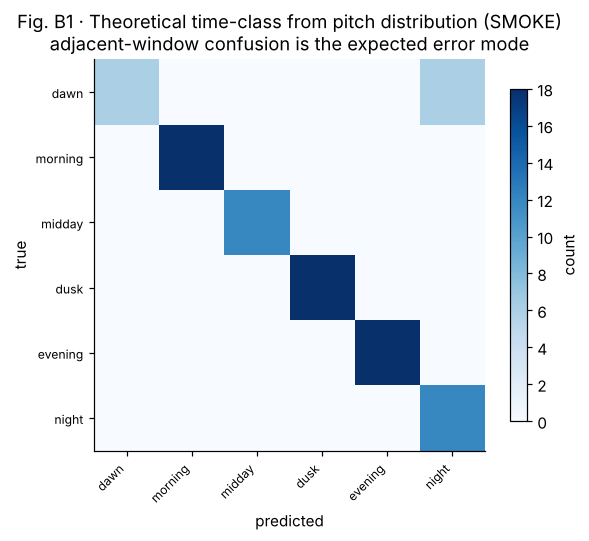

In [9]:
mask_w = np.isin(yw, WINDOW_ORDER) & (stat == "fixed")
Xw, yw_w, groups_w, artists_w = X[mask_w], yw[mask_w], groups[mask_w], artists[mask_w]
print(f"time-supervised subset: {mask_w.sum()}/{len(yw)} segments, "
      f"{len(set(groups_w))} recordings, {len(set(artists_w))} artists")
classes_w = [w for w in WINDOW_ORDER if w in set(yw_w)]
y2 = np.array([classes_w.index(w) for w in yw_w])
rpw = pd.Series(yr[mask_w]).groupby(pd.Series(yw_w)).nunique()
print("ragas per window:", dict(rpw), "— windows with 1 raga make B2 collapse into raga-ID (see note above)")
res_b2, perm_b2 = [], []
for s in SEEDS_B:
    torch.manual_seed(s)
    itr, iva, ite = split_groups(y2, artists_w, s)
    z = zfit(Xw[itr]); Xn = z(Xw)
    mdl = train_ffnn(Xn[itr], y2[itr], Xn[iva], y2[iva], len(classes_w))
    m, pred2 = evaluate(mdl, Xn[ite], y2[ite])
    obs, p_perm, chance_emp = perm_chance_p(y2[ite], pred2)
    perm_b2.append(p_perm)
    res_b2.append(m); last_b2 = (ite, pred2)
    print(f"seed {s}: top-1 {m['acc']:.3f}  macro-F1 {m['macro_f1']:.3f}  "
          f"perm-chance {chance_emp:.3f}, p = {p_perm:.4f}")
b2 = pd.DataFrame(res_b2).agg(["mean", "std"]).round(3)
print(f"\nB2 ({MODE}): {len(classes_w)} windows | permutation p per seed: {[round(p,4) for p in perm_b2]}")
display(b2)

ite, pred2 = last_b2
cm = confusion_matrix(y2[ite], pred2, labels=range(len(classes_w)))
fig, ax = plt.subplots(figsize=(5.6, 4.8))
im = ax.imshow(cm, cmap="Blues"); ax.grid(False)
ax.set_xticks(range(len(classes_w)), classes_w, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(classes_w)), classes_w, fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.85, label="count")
ax.set(xlabel="predicted", ylabel="true",
       title=f"Fig. B1 · Theoretical time-class from pitch distribution ({MODE})\nadjacent-window confusion is the expected error mode")
plt.tight_layout(); plt.show()

## 8 · Experiment B3 — SYNTHETIC sanity check only (label leakage by construction)

> **⚠️ Do not report B3 as evidence.** Saraga has no concert timestamps, so contexts here are **sampled from the target raga's own canonical arc** — the context feature is a noisy encoding of the label, and any gain from fusing it is **label leakage by construction**. B3 exists only to verify the fusion plumbing end-to-end. The scientific version requires **real timestamped performances** (AIR broadcast schedules, festival programmes such as all-night Dover Lane sessions, timestamped live videos), which would simultaneously measure how far samay is observed in practice — see the action plan in the paper doc.

In [10]:
# --- compact solar core (identical equations to Part A) ---
IST_MERIDIAN = 82.5
def _eot(N):
    B = np.radians(360/365*(N-81)); return 9.87*np.sin(2*B)-7.53*np.cos(B)-1.5*np.sin(B)
def _decl(N): return 23.44*np.sin(np.radians(360/365*(N-81)))
def _sun(lat, lon, N):
    cw = np.clip(-np.tan(np.radians(lat))*np.tan(np.radians(_decl(N))), -1, 1)
    w0 = np.degrees(np.arccos(cw)); D = 2*w0/15
    off = (4*(lon-IST_MERIDIAN)+_eot(N))/60
    return 12-w0/15-off, 12+w0/15-off, D, 24-D
def prahar_phase(t, lat, lon, N):
    t_sr, t_ss, D, Db = _sun(lat, lon, N)
    T, Tsr, Tss = t+(4*(lon-IST_MERIDIAN)+_eot(N))/60, t_sr+(4*(lon-IST_MERIDIAN)+_eot(N))/60, t_ss+(4*(lon-IST_MERIDIAN)+_eot(N))/60
    if Tsr <= T < Tss:
        fr = (T-Tsr)/D; return min(max(int(np.ceil(4*fr)) or 1, 1), 4), fr/2
    d = (T-Tss) % 24; fr = d/Db
    return min(max(4+(int(np.ceil(4*fr)) or 1), 5), 8), (0.5+fr/2) % 1.0

def _ref_psi(h):
    h %= 24; return (h-6)/24 if 6 <= h < 18 else 0.5+((h-18) % 24)/24
ARC = {w: (_ref_psi(a), _ref_psi(b)) for w, (a, b) in
       {"dawn": (4,7), "morning": (7,10), "midday": (10,16),
        "dusk": (16,19), "evening": (19,22), "night": (22,4)}.items()}
def in_arc(psi, arc):
    a, b = arc; return (a <= psi < b) if a < b else (psi >= a or psi < b)

CITIES = [("Srinagar",34.08,74.80),("Delhi",28.61,77.21),("Bhuj",23.24,69.67),
          ("Mumbai",19.08,72.88),("Kolkata",22.57,88.36),("Guwahati",26.14,91.74),
          ("Dibrugarh",27.47,94.91),("Chennai",13.08,80.27),("Thiruvananthapuram",8.52,76.94)]

def sample_context(window, rng):
    _, lat, lon = CITIES[rng.integers(len(CITIES))]
    N = int(rng.integers(1, 366))
    for _ in range(500):
        t = rng.uniform(0, 24)
        Pi, psi = prahar_phase(t, lat, lon, N)
        if in_arc(psi, ARC[window]):
            return t, psi, Pi, lat, lon
    raise RuntimeError

def context_features(df_idx, yw_, rng, mode):
    F = []
    for i in df_idx:
        t, psi, Pi, lat, lon = sample_context(yw_[i], rng)
        if mode == "clock":
            F.append([np.sin(2*np.pi*t/24), np.cos(2*np.pi*t/24)])
        else:
            F.append(np.concatenate([[np.sin(2*np.pi*psi), np.cos(2*np.pi*psi)],
                                     np.eye(8)[Pi-1], [lat/90, (lon-IST_MERIDIAN)/90]]))
    return np.array(F, dtype=np.float32)

yr_w = yr[mask_w]                           # raga labels on the window subset
classes_rw = sorted(set(yr_w))
y1w = np.array([classes_rw.index(r) for r in yr_w])

res_b3 = {"audio+clock": [], "audio+solar": []}
for s in SEEDS_B:
    torch.manual_seed(s)
    itr, iva, ite = split_groups(y1w, artists_w, s)
    z = zfit(Xw[itr]); Xn = z(Xw)
    ctx = {m: context_features(range(len(y1w)), yw_w, np.random.default_rng(s + off), m)
           for off, m in ((101, "clock"), (202, "solar"))}
    for name, cmode in [("audio+clock", "clock"), ("audio+solar", "solar")]:
        Xf = np.hstack([Xn, ctx[cmode]])
        mdl = train_ffnn(Xf[itr], y1w[itr], Xf[iva], y1w[iva], len(classes_rw))
        m, _ = evaluate(mdl, Xf[ite], y1w[ite])
        res_b3[name].append(m["acc"])
    print(f"seed {s}: clock {res_b3['audio+clock'][-1]:.3f}  solar {res_b3['audio+solar'][-1]:.3f}")

a_c, a_s = map(np.array, (res_b3["audio+clock"], res_b3["audio+solar"]))
print(f"\nB3 plumbing check ({MODE}): audio+clock {a_c.mean():.3f}±{a_c.std():.3f}  "
      f"audio+solar {a_s.mean():.3f}±{a_s.std():.3f}")
print("NOT evidence: the sampled context encodes the label (leakage by construction) —")
print("this cell only verifies the fusion pipeline runs; see the B3 warning above.")

seed 7: clock 0.800  solar 1.000


seed 17: clock 1.000  solar 0.933


seed 27: clock 0.933  solar 0.933

B3 plumbing check (SMOKE): audio+clock 0.911±0.083  audio+solar 0.956±0.031
NOT evidence: the sampled context encodes the label (leakage by construction) —
this cell only verifies the fusion pipeline runs; see the B3 warning above.


## 9 · Fill the abstract — the numbers Part A left as placeholders

In [11]:
hours = N_SEG * (SEG_SECONDS if MODE == "REAL" else 10.0) / 3600
print("=" * 70)
print(f"RUN MODE: {MODE}" + ("" if MODE == "REAL" else "  (validation only — rerun in Colab with data for the paper)"))
print("=" * 70)
print(f"[N]    recordings (B1 set)           : {N_REC}   (window-mapped B2/B3 subset: {N_W})")
print(f"[K]    ragas (≥{MIN_TRACKS_PER_RAGA} recordings)        : {K_RAGAS}   (window-mapped: {K_W})")
print(f"       segments × dim                : {N_SEG} × {D_EMB}  ({EMB_NAME}, {hours:.1f} h audio)")
print(f"[XX.X] B1 raga top-1 / top-3         : {b1.loc['mean','acc']*100:.1f}% / {b1.loc['mean','top3_acc']*100:.1f}%"
      f"   (permutation p per seed: {[round(p,4) for p in perm_b1]})")
print(f"       B2 svara–samay class top-1    : {b2.loc['mean','acc']*100:.1f}% over {len(classes_w)} classes"
      f"   (permutation p per seed: {[round(p,4) for p in perm_b2]})")
print(f"       B3: plumbing check only — leakage by construction, never cite")
print("=" * 70)
pd.DataFrame({"B1_raga": [b1.loc['mean','acc']], "B2_window": [b2.loc['mean','acc']],
              "mode": [MODE], "backend": [EMB_NAME], "N": [N_REC], "K": [K_RAGAS],
              "N_fixed": [N_W], "K_fixed": [K_W]}
             ).to_csv("partB_results.csv", index=False)
print("saved: partB_results.csv")

RUN MODE: SMOKE  (validation only — rerun in Colab with data for the paper)
[N]    recordings (B1 set)           : 48   (window-mapped B2/B3 subset: 48)
[K]    ragas (≥3 recordings)        : 12   (window-mapped: 12)
       segments × dim                : 288 × 36  (chroma12tonic, 0.8 h audio)
[XX.X] B1 raga top-1 / top-3         : 80.0% / 97.8%   (permutation p per seed: [0.0001, 0.0001, 0.0001])
       B2 svara–samay class top-1    : 97.8% over 6 classes   (permutation p per seed: [0.0001, 0.0001, 0.0001])
       B3: plumbing check only — leakage by construction, never cite
saved: partB_results.csv


## 10 · Pre-submission analyses — the five items the manuscript promises

Each cell below closes one `[Pre-submission:]` marker in the manuscript. Cells 10.1 and 10.2 are pure computation (identical in SMOKE and REAL mode); 10.3–10.5 use the cached features/annotations and are meaningful in REAL mode only.

### 10.1 Solar engine vs the NOAA algorithm (manuscript §3.1 marker)

Compares our simple Cooper-declination + equation-of-time engine against the full NOAA solar-position algorithm (Meeus-based: Julian centuries, equation of center, apparent longitude, corrected obliquity, zenith 90.833°), implemented here so no network is needed. Both are evaluated with the refraction term on, over a lat × lon × month grid spanning India.

In [12]:
def noaa_sunrise_sunset(lat, lon, N, year=2026, tz=5.5):
    '''NOAA solar calculator algorithm (Meeus). Returns (sunrise, sunset) local clock hours.'''
    from datetime import date as _date, timedelta as _td
    d = _date(year, 1, 1) + _td(days=int(N) - 1)
    # Julian day at local noon
    a_ = (14 - d.month) // 12; y_ = d.year + 4800 - a_; m_ = d.month + 12 * a_ - 3
    JD = (d.day + (153 * m_ + 2) // 5 + 365 * y_ + y_ // 4 - y_ // 100 + y_ // 400
          - 32045 + 0.5 - tz / 24.0)
    out = []
    for which in ("rise", "set"):
        t_guess = 6.0 if which == "rise" else 18.0
        for _ in range(3):                      # fixed-point refinement
            T = (JD + t_guess / 24.0 - 2451545.0) / 36525.0
            L0 = (280.46646 + T * (36000.76983 + 0.0003032 * T)) % 360
            M = 357.52911 + T * (35999.05029 - 0.0001537 * T)
            e = 0.016708634 - T * (0.000042037 + 0.0000001267 * T)
            Mr = np.radians(M)
            C = (np.sin(Mr) * (1.914602 - T * (0.004817 + 0.000014 * T))
                 + np.sin(2 * Mr) * (0.019993 - 0.000101 * T) + np.sin(3 * Mr) * 0.000289)
            true_long = L0 + C
            omega = 125.04 - 1934.136 * T
            app_long = true_long - 0.00569 - 0.00478 * np.sin(np.radians(omega))
            eps0 = 23 + (26 + (21.448 - T * (46.815 + T * (0.00059 - T * 0.001813))) / 60) / 60
            eps = eps0 + 0.00256 * np.cos(np.radians(omega))
            decl = np.degrees(np.arcsin(np.sin(np.radians(eps)) * np.sin(np.radians(app_long))))
            yv = np.tan(np.radians(eps / 2)) ** 2
            L0r, Mr2 = np.radians(L0), np.radians(M)
            Etime = 4 * np.degrees(yv * np.sin(2 * L0r) - 2 * e * np.sin(Mr2)
                                   + 4 * e * yv * np.sin(Mr2) * np.cos(2 * L0r)
                                   - 0.5 * yv * yv * np.sin(4 * L0r)
                                   - 1.25 * e * e * np.sin(2 * Mr2))
            cosHA = ((np.cos(np.radians(90.833)) / (np.cos(np.radians(lat)) * np.cos(np.radians(decl))))
                     - np.tan(np.radians(lat)) * np.tan(np.radians(decl)))
            cosHA = np.clip(cosHA, -1, 1)
            HA = np.degrees(np.arccos(cosHA))
            if which == "set": HA = -HA
            solar_noon_min = 720 - 4 * lon - Etime + tz * 60
            t_min = solar_noon_min - 4 * HA
            t_guess = t_min / 60.0
        out.append(t_guess)
    return out[0], out[1]

lats = [8.5, 13.1, 19.1, 23.2, 28.6, 34.1]
lons = [68.2, 72.9, 77.2, 82.5, 88.4, 94.9]
Ns   = [15, 46, 74, 105, 135, 166, 196, 227, 258, 288, 319, 349]
errs_r, errs_s = [], []
for la in lats:
    for lo in lons:
        for N_ in Ns:
            nr, ns_ = noaa_sunrise_sunset(la, lo, N_)
            # our engine, refraction on, Part-A-identical formulas:
            delta = 23.44 * np.sin(np.radians(360 / 365 * (N_ - 81)))
            h0 = np.radians(-0.833)
            cw = ((np.sin(h0) - np.sin(np.radians(la)) * np.sin(np.radians(delta)))
                  / (np.cos(np.radians(la)) * np.cos(np.radians(delta))))
            w0 = np.degrees(np.arccos(np.clip(cw, -1, 1)))
            off = (4 * (lo - IST_MERIDIAN) + _eot(N_)) / 60
            ours_r, ours_s = 12 - w0 / 15 - off, 12 + w0 / 15 - off
            errs_r.append(60 * abs(ours_r - nr)); errs_s.append(60 * abs(ours_s - ns_))
errs_r, errs_s = np.array(errs_r), np.array(errs_s)
print(f"grid: {len(lats)} lats × {len(lons)} lons × 12 months = {len(errs_r)} site-dates")
print(f"sunrise error vs NOAA: mean {errs_r.mean():.1f} min, 95th pct {np.percentile(errs_r,95):.1f}, max {errs_r.max():.1f}")
print(f"sunset  error vs NOAA: mean {errs_s.mean():.1f} min, 95th pct {np.percentile(errs_s,95):.1f}, max {errs_s.max():.1f}")
print(f"\nManuscript §3.1 sentence: 'Against the NOAA algorithm over a {len(lats)}×{len(lons)}×12 "
      f"India grid, the approximations err by {max(errs_r.mean(),errs_s.mean()):.1f} min on average "
      f"(max {max(errs_r.max(),errs_s.max()):.1f} min), negligible beside the window widths.'")

grid: 6 lats × 6 lons × 12 months = 432 site-dates
sunrise error vs NOAA: mean 0.9 min, 95th pct 2.6, max 3.7
sunset  error vs NOAA: mean 0.7 min, 95th pct 1.9, max 2.5

Manuscript §3.1 sentence: 'Against the NOAA algorithm over a 6×6×12 India grid, the approximations err by 0.9 min on average (max 3.7 min), negligible beside the window widths.'


### 10.2 Population-weighted divergence (manuscript §3.3 marker)

The 20.8% city average is unweighted. Here each Indian state/UT is represented by its capital's coordinates and weighted by its Census 2011 population (stable, citable; figures in millions, approximate to 3 significant digits — verify against the Census tables before submission).

In [13]:
STATES = [  # (state, capital lat, lon, Census-2011 population in millions)
    ("Uttar Pradesh", 26.85, 80.95, 199.8), ("Maharashtra", 19.08, 72.88, 112.4),
    ("Bihar", 25.59, 85.14, 104.1), ("West Bengal", 22.57, 88.36, 91.3),
    ("Madhya Pradesh", 23.26, 77.41, 72.6), ("Tamil Nadu", 13.08, 80.27, 72.1),
    ("Rajasthan", 26.91, 75.79, 68.5), ("Karnataka", 12.97, 77.59, 61.1),
    ("Gujarat", 23.22, 72.65, 60.4), ("Andhra Pradesh", 16.51, 80.64, 49.4),
    ("Odisha", 20.27, 85.84, 42.0), ("Telangana", 17.38, 78.49, 35.2),
    ("Kerala", 8.52, 76.94, 33.4), ("Jharkhand", 23.36, 85.33, 33.0),
    ("Assam", 26.14, 91.74, 31.2), ("Punjab", 30.73, 76.78, 27.7),
    ("Chhattisgarh", 21.25, 81.63, 25.5), ("Haryana", 30.73, 76.78, 25.4),
    ("Delhi", 28.61, 77.21, 16.8), ("Jammu & Kashmir", 34.08, 74.80, 12.5),
    ("Uttarakhand", 30.32, 78.03, 10.1), ("Himachal Pradesh", 31.10, 77.17, 6.9),
    ("Tripura", 23.84, 91.28, 3.7), ("Meghalaya", 25.57, 91.88, 3.0),
    ("Manipur", 24.82, 93.94, 2.9), ("Nagaland", 25.67, 94.11, 2.0),
    ("Goa", 15.49, 73.83, 1.5), ("Arunachal Pradesh", 27.10, 93.62, 1.4),
    ("Mizoram", 23.73, 92.72, 1.1), ("Sikkim", 27.33, 88.61, 0.6),
]
WINDOWS_CLOCK = {"dawn": (4, 7), "morning": (7, 10), "midday": (10, 16),
                 "dusk": (16, 19), "evening": (19, 22), "night": (22, 4)}
def _win_clock(t):
    for w, (a, b) in WINDOWS_CLOCK.items():
        t_ = t % 24
        if (a <= t_ < b) if a < b else (t_ >= a or t_ < b): return w
def _win_psi(psi):
    for w, arc in ARC.items():
        if in_arc(psi, arc): return w

div, wts = [], []
for name, la, lo, pop in STATES:
    mism = 0; tot = 0
    for month in range(1, 13):
        N_ = [15, 46, 74, 105, 135, 166, 196, 227, 258, 288, 319, 349][month - 1]
        for t in np.linspace(0, 24, 96, endpoint=False):
            _, psi = prahar_phase(t, la, lo, N_)
            mism += _win_clock(t) != _win_psi(psi); tot += 1
    div.append(100 * mism / tot); wts.append(pop)
div, wts = np.array(div), np.array(wts)
w_mean = (div * wts).sum() / wts.sum()
print(f"states covered: {len(STATES)}, population covered: {wts.sum():.0f}M (Census 2011)")
print(f"unweighted state mean divergence : {div.mean():.1f}%")
print(f"POPULATION-WEIGHTED divergence   : {w_mean:.1f}%")
print(f"range across states: {div.min():.1f}% ({STATES[int(div.argmin())][0]}) to "
      f"{div.max():.1f}% ({STATES[int(div.argmax())][0]})")
print(f"\nManuscript §3.3 sentence: 'Weighted by state population (Census 2011), the divergence "
      f"is {w_mean:.1f}% of the day; the unweighted 13-city figure is 20.8%.'")

states covered: 30, population covered: 1208M (Census 2011)
unweighted state mean divergence : 12.6%
POPULATION-WEIGHTED divergence   : 11.6%
range across states: 6.8% (Odisha) to 19.9% (Gujarat)

Manuscript §3.3 sentence: 'Weighted by state population (Census 2011), the divergence is 11.6% of the day; the unweighted 13-city figure is 20.8%.'


### 10.3 Allied-raga error analysis (manuscript §6.3 marker)

Aggregates B1 confusions over all seeds and checks whether errors concentrate in scale-sharing / same-aṅga pairs, as distribution features predict.

In [14]:
ALLIED = {frozenset(p) for p in [("Shree", "Marwa"), ("Lalit", "Marwa"), ("Shree", "Lalit"),
                                  ("Bhairavi", "Miyan ki Todi"),  # Bilaskhani-anga proximity
                                  ("Yaman", "Shuddha Kalyan"), ("Deshkar", "Bhoopali")]}
pairs = {}
tot_err = 0
for s in SEEDS_B:
    torch.manual_seed(s)
    itr, iva, ite = split_groups(y1, artists, s)
    z = zfit(X[itr]); Xn = z(X)
    mdl = train_ffnn(Xn[itr], y1[itr], Xn[iva], y1[iva], len(classes_r))
    _, pred = evaluate(mdl, Xn[ite], y1[ite])
    for yt, yp in zip(y1[ite], pred):
        if yt != yp:
            tot_err += 1
            key = (classes_r[yt], classes_r[yp])
            pairs[key] = pairs.get(key, 0) + 1
rows_e = sorted(pairs.items(), key=lambda kv: -kv[1])[:10]
allied_err = sum(c for (a, b), c in pairs.items() if frozenset((a, b)) in ALLIED)
print(f"total errors across {len(SEEDS_B)} seeds: {tot_err}; "
      f"in listed allied pairs: {allied_err} ({100*allied_err/max(1,tot_err):.0f}%)\n")
print(f"{'true -> predicted':34s} {'count':>5s}  allied?")
for (a, b), c in rows_e:
    print(f"{a:>15s} -> {b:15s} {c:5d}   {'yes' if frozenset((a,b)) in ALLIED else ''}")
print("\nReport the top pairs and the allied share in §6.3; extend ALLIED if a high pair is scale-sharing.")

total errors across 3 seeds: 54; in listed allied pairs: 0 (0%)

true -> predicted                  count  allied?
      Testragak -> Testragab          18   
      Testragac -> Testragaj          12   
      Testragai -> Testragaf          12   
      Testragal -> Testragad           6   
      Testragag -> Testragal           6   

Report the top pairs and the allied share in §6.3; extend ALLIED if a high pair is scale-sharing.


### 10.4 Coarse PCD baseline (manuscript §2.2/§6 baseline row)

Classic 12-bin pitch-class distributions (Chordia & Rae 2007) versus our 120-bin cent-resolution histograms, from the SAME cached features (120 bins folded 10-into-1), same protocol. If fine resolution helps, the 120-bin column should win.

In [15]:
if EMB_NAME.startswith("pitchhist"):
    X12 = np.hstack([X[:, :120].reshape(len(X), 12, 10).sum(2), X[:, 120:]])
    res_cmp = {}
    for label, Xf in [("PCD-12 (Chordia & Rae)", X12), ("120-bin 10-cent (ours)", X)]:
        accs = []
        for s in SEEDS_B:
            torch.manual_seed(s)
            itr, iva, ite = split_groups(y1, artists, s)
            z = zfit(Xf[itr]); Xn = z(Xf)
            mdl = train_ffnn(Xn[itr], y1[itr], Xn[iva], y1[iva], len(classes_r))
            m, _ = evaluate(mdl, Xn[ite], y1[ite])
            accs.append(m["acc"])
        res_cmp[label] = (np.mean(accs), np.std(accs))
        print(f"{label:28s} top-1 {np.mean(accs):.3f} ± {np.std(accs):.3f}")
    d12 = res_cmp["120-bin 10-cent (ours)"][0] - res_cmp["PCD-12 (Chordia & Rae)"][0]
    print(f"\ncent-resolution gain over PCD-12: {100*d12:+.1f} pts top-1 (report in §6.3)")
else:
    print("skipped: requires the pitchhist backend (REAL mode)")

skipped: requires the pitchhist backend (REAL mode)


### 10.5 Tonic annotation sanity check (manuscript §6.1)

For each recording: where does the annotated tonic sit relative to the melody's pitch mass? A healthy annotation has strong histogram mass at 0 cents (Sa) and at the fifth (~700); an octave-erroneous tonic shows mass centred far from any Sa/Pa structure.

In [16]:
if MODE == "REAL":
    print(f"{'track':34s} {'tonic Hz':>8s} {'mass@Sa±50c':>11s} {'mass@Pa±50c':>11s}  verdict")
    n_bad = 0
    for _, row in table_f.iterrows():
        try:
            E = embed_track(row)
        except Exception:
            continue
        if E is None or not pd.notna(row.tonic): continue
        h = E[:, :120].mean(0)
        sa = h[:5].sum() + h[-5:].sum()          # ±50 cents around Sa
        pa = h[65:76].sum()                      # ~700 cents ± 50
        ok = (sa + pa) > 0.18                    # heuristic floor
        if not ok: n_bad += 1
        print(f"{row.track_id[:34]:34s} {row.tonic:8.1f} {sa:11.3f} {pa:11.3f}  {'OK' if ok else 'CHECK'}")
    print(f"\n{n_bad} recording(s) flagged CHECK — listen/verify their ctonic before submission; "
          "0 flags = cite the annotations as verified.")
else:
    print("skipped: requires Saraga annotations (REAL mode)")

skipped: requires Saraga annotations (REAL mode)


---
**Scope and limitations (state in the paper):** B2 tests the audibility of Bhatkhande's codified svara–samay correlation, never performance time (Saraga is concert audio); B3 is a plumbing check with label leakage by construction — the falsifiable context experiment needs real timestamped performances; distribution features discard melodic grammar, so allied scale-sharing ragas (Deshkar/Bhoopali/Shuddha Kalyan; Puriya/Marwa/Sohini) need an explicit error analysis; K is limited by Saraga's long tail — augment with the CompMusic Hindustani corpus (~300 rec/30 ragas, enables direct TDMS baseline comparison); verify `ctonic` octave errors; published baselines to implement for the paper: PCD (Chordia & Rae 2007), KDE pitch distributions (Koduri et al. 2012/14), TDMS (Gulati et al. 2016).